# Exploratory data analysis: hourly bike rentals

**Question:** What do the recorded hourly rentals reveal about data quality, demand and candidate forecasting inputs? This notebook follows the standard EDA sequence: understand the dataset, audit quality, inspect distributions, examine relationships, study time dependence, then summarize implications. The final section separates observed facts from pipeline choices that still need validation.

Initial structure, quality and target distribution checks use the full dataset. After defining evaluation periods, analyses that could guide feature or window choices use training rows only. Validation and test labels are never used to select preprocessing. Run from the repository root or the `notebooks` directory.

## 1. Load data and understand its structure

`hour.csv` has one record per observed hour. `cnt` is the target. First inspect the full raw dataset; no model split is needed for this descriptive audit.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd() if (Path.cwd() / 'data/hour.csv').exists() else Path.cwd().parent
df = pd.read_csv(root / 'data/hour.csv').sort_values(['dteday', 'hr']).reset_index(drop=True)
df['timestamp'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], unit='h')


In [2]:
display(df.head())
display(pd.DataFrame({'dtype':df.dtypes.astype(str),
                      'missing':df.isna().sum(),
                      'unique':df.nunique()}))
print('Shape:', df.shape, '| timestamp range:', df.timestamp.min(), 'to', df.timestamp.max())
print('Target identity holds:', bool((df.cnt == df.casual + df.registered).all()))

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00


,dtype,missing,unique
instant,int64,0,17379
dteday,str,0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
hr,int64,0,24
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,4


Shape: (17379, 18) | timestamp range: 2011-01-01 00:00:00 to 2012-12-31 23:00:00
Target identity holds: True


## 2. Data quality

Check missing cells, duplicate timestamps, absent hours and the impact of gaps on complete 24-input/5-target windows. Missing *cells* and missing *hourly records* are different.

In [3]:
missing_cells = df.isna().sum().sort_values(ascending=False)
gap_hours = df.timestamp.diff().dt.total_seconds().div(3600)
gaps = (gap_hours[gap_hours > 1] - 1).astype(int)
print('Missing cells:', int(missing_cells.sum()), '| duplicate timestamps:', int(df.timestamp.duplicated().sum()))
print('Gap events:', len(gaps), '| absent hours:', int(gaps.sum()))
display(gaps.value_counts().sort_index().rename_axis('absent hours per gap').to_frame('gaps'))
missing_index = pd.date_range(df.timestamp.min(), df.timestamp.max(), freq='h').difference(df.timestamp)
display(pd.DataFrame({'missing_hours':pd.Series(missing_index.hour).value_counts().reindex(range(24),fill_value=0),
                      'observed_hours':df.hr.value_counts().reindex(range(24),fill_value=0)}))



Missing cells: 0 | duplicate timestamps: 0
Gap events: 75 | absent hours: 165


,gaps
absent hours per gap,
1,64
2,6
6,1
12,1
13,1
22,1
36,1


,missing_hours,observed_hours
0,5,726
1,7,724
2,16,715
3,34,697
4,34,697
5,14,717
6,6,725
7,4,727
8,4,727
9,4,727


## 3. Univariate analysis

Inspect the full dataset's target scale, spread and tail. This describes the collected data; it is not used to tune preprocessing. High values are genuine observations unless the source gives evidence of recording errors.

,cnt
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
1%,2.000000
5%,5.000000
25%,40.000000
50%,142.000000
75%,281.000000
95%,563.100000


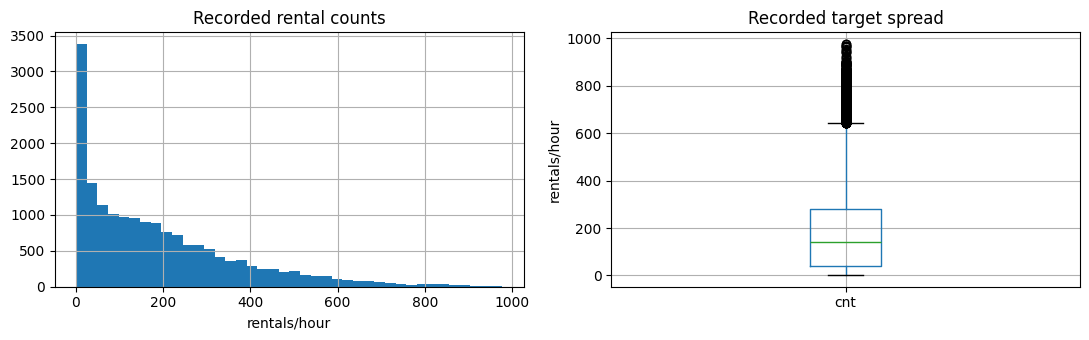

In [4]:
display(df.cnt.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_frame('cnt'))
fig, ax = plt.subplots(1,2,figsize=(11,3.5))
df.cnt.hist(bins=40,ax=ax[0]); ax[0].set(title='Recorded rental counts',xlabel='rentals/hour')
df.boxplot(column='cnt',ax=ax[1]); ax[1].set(title='Recorded target spread',ylabel='rentals/hour')
plt.tight_layout(); plt.show()

## 4. Define chronological evaluation periods

From this point onward, analyses that could guide feature or window choices use **training rows only**. The existing pipeline uses a 70/15/15 chronological holdout. Validation is reserved for comparisons; test is reserved for final evaluation. The window audit includes historical context from the preceding split, as in the pipeline.

In [5]:
n = len(df)
train_end, val_end = int(.70*n), int(.85*n)
train = df.iloc[:train_end].copy()
val = df.iloc[train_end:val_end].copy()
test = df.iloc[val_end:].copy()
display(pd.DataFrame({'rows':[len(train),len(val),len(test)],
                      'start':[p.timestamp.min() for p in (train,val,test)],
                      'end':[p.timestamp.max() for p in (train,val,test)]},
                     index=['train','validation','test']))

,rows,start,end
train,12165,2011-01-01 00:00:00,2012-05-27 01:00:00
validation,2607,2012-05-27 02:00:00,2012-09-12 16:00:00
test,2607,2012-09-12 17:00:00,2012-12-31 23:00:00


In [6]:
def window_audit(part, input_len=24, horizon=5):
    possible = max(0, len(part)-input_len-horizon+1)
    good = 0
    for i in range(possible):
        t = part.timestamp.iloc[i:i+input_len+horizon]
        good += bool(t.diff().iloc[1:].eq(pd.Timedelta(hours=1)).all())
    return possible, good

audit = []
for name, part in [('train',train),
                   ('validation',df.iloc[train_end-24:val_end]),
                   ('test',df.iloc[val_end-24:])]:
    possible, kept = window_audit(part)
    audit.append((name,possible,kept,possible-kept,100*(possible-kept)/possible))
display(pd.DataFrame(audit,columns=['split','candidate windows','kept','discarded','discarded %']))

,split,candidate windows,kept,discarded,discarded %
0,train,12137,10404,1733,14.278652
1,validation,2603,2603,0,0.000000
2,test,2603,2469,134,5.147906


## 5. Bivariate and group comparisons

Compare training demand with calendar and weather variables. Same-hour associations are descriptive; they cannot establish feature importance for a five-hour forecast.

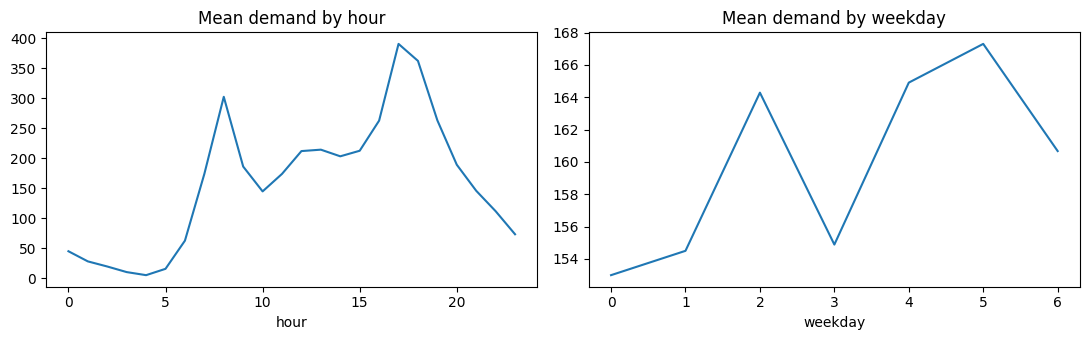

,same-hour r
cnt,1.000000
temp,0.399184
atemp,0.398619
hum,-0.300855
windspeed,0.094443
weathersit,-0.150838
hr,0.397088
weekday,0.023027
mnth,0.071003


In [7]:
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
train.groupby('hr').cnt.mean().plot(ax=ax[0]); ax[0].set(title='Mean demand by hour',xlabel='hour')
train.groupby('weekday').cnt.mean().plot(ax=ax[1]); ax[1].set(title='Mean demand by weekday',xlabel='weekday')
plt.tight_layout(); plt.show()
numeric = ['cnt','temp','atemp','hum','windspeed','weathersit','hr','weekday','mnth']
display(train[numeric].corr(numeric_only=True)['cnt'].rename('same-hour r').to_frame())


## 6. Time series patterns and lag dependence

Inspect the training monthly trend and correlations at actual hourly lags. Reindexing to hourly timestamps prevents row offsets across gaps from masquerading as time lags. Raw autocorrelation can reflect trend and seasonality; it is descriptive, not a model-selection score.

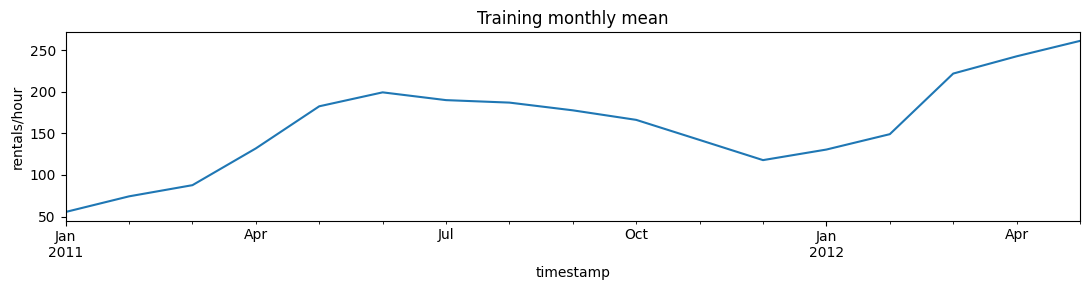

,lag hours,observed pairs,Pearson r
0,1,12094,0.840402
1,12,12039,-0.168616
2,24,12033,0.799844
3,48,12006,0.666125
4,72,11984,0.626148
5,168,11900,0.854394


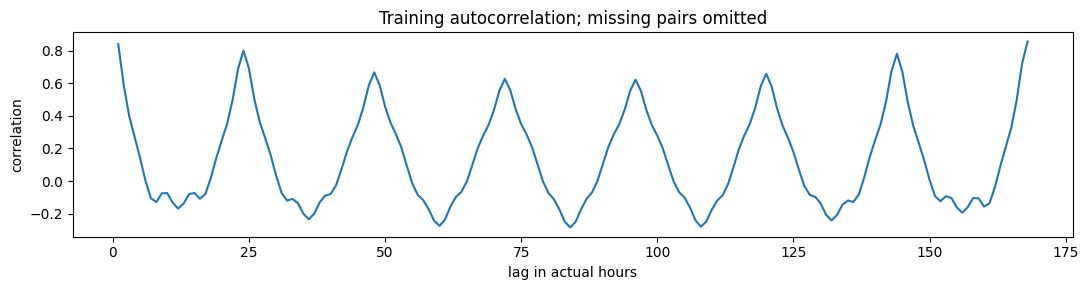

In [8]:
fig,ax=plt.subplots(figsize=(11,3))
train.set_index('timestamp').cnt.resample('MS').mean().plot(ax=ax)
ax.set(title='Training monthly mean',ylabel='rentals/hour'); plt.tight_layout(); plt.show()
series = train.set_index('timestamp').cnt.asfreq('h')
lag_rows = []
for lag in [1,12,24,48,72,168]:
    paired = pd.concat([series,series.shift(lag)],axis=1).dropna()
    lag_rows.append((lag,len(paired),paired.iloc[:,0].corr(paired.iloc[:,1])))
display(pd.DataFrame(lag_rows,columns=['lag hours','observed pairs','Pearson r']))
fig,ax=plt.subplots(figsize=(11,3));
pd.Series({lag:series.corr(series.shift(lag)) for lag in range(1,169)}).plot(ax=ax)
ax.set(xlabel='lag in actual hours',ylabel='correlation',title='Training autocorrelation; missing pairs omitted');
plt.tight_layout(); plt.show()

## 7. Target components and feature redundancy

Historical `casual` and `registered` values are available at the forecast origin. Their exact sum equals historical `cnt`, but that does not prove they have no predictive value. Future component values are unavailable and must never be inputs.

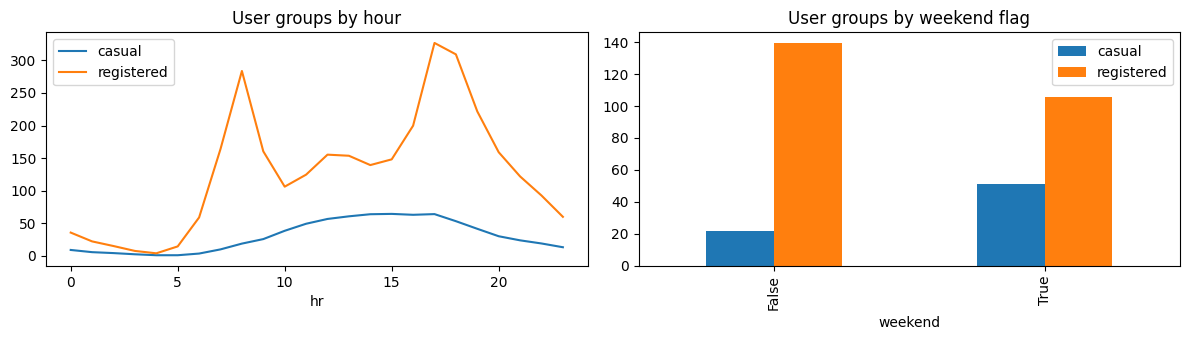

cnt = casual + registered in all rows: True


,next-hour r
cnt,0.840402
casual,0.655649
registered,0.790503


In [9]:
profile = train.groupby(['weekday','hr'])[['cnt','casual','registered']].mean()
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
train.groupby('hr')[['casual','registered']].mean().plot(ax=ax[0]); ax[0].set(title='User groups by hour')
train.assign(weekend=train.weekday.isin([0,6])).groupby('weekend')[['casual','registered']].mean().plot.bar(ax=ax[1]); ax[1].set(title='User groups by weekend flag')
plt.tight_layout(); plt.show()
print('cnt = casual + registered in all rows:', bool((df.cnt == df.casual + df.registered).all()))
future = train.set_index('timestamp').cnt.asfreq('h').shift(-1)
lagged = train.set_index('timestamp')[['cnt','casual','registered']].asfreq('h')
display(lagged.assign(next_hour_cnt=future).corr()['next_hour_cnt'].drop('next_hour_cnt').to_frame('next-hour r'))

## 8. Temporal distribution shift and split audit

These validation and test summaries describe the evaluation periods. They must not guide feature or window selection. The monthly plot shows why a single holdout cutoff may be sensitive to period composition.

,rows,mean cnt,median cnt,p95 cnt
train,12165,159.93,119.0,470.8
validation,2607,281.04,251.0,719.0
test,2607,235.68,186.0,685.1


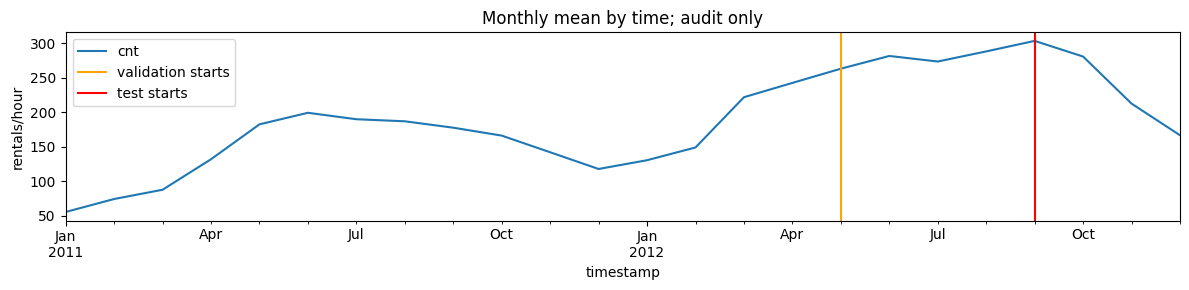

In [10]:
display(pd.DataFrame({'rows':[len(p) for p in (train,val,test)],
                      'mean cnt':[p.cnt.mean() for p in (train,val,test)],
                      'median cnt':[p.cnt.median() for p in (train,val,test)],
                      'p95 cnt':[p.cnt.quantile(.95) for p in (train,val,test)]},
                     index=['train','validation','test']).round(2))
fig,ax=plt.subplots(figsize=(12,3))
df.set_index('timestamp').cnt.resample('MS').mean().plot(ax=ax)
ax.axvline(val.timestamp.min(),color='orange',label='validation starts')
ax.axvline(test.timestamp.min(),color='red',label='test starts')
ax.set(title='Monthly mean by time; audit only',ylabel='rentals/hour'); ax.legend(); plt.tight_layout(); plt.show()



## 9. EDA findings and forecasting design

The table below is a decision register, not a claim that the best configuration has been found. The existing pipeline uses complete windows, 24 hours of input and a single chronological holdout. Train-only scaler fitting and observed target labels are required for valid evaluation.

### Decision register

| Question | Evidence available here | Validation needed | Current status |
|---|---|---|---|
| Missing hours | Gap lengths and discarded-window rate | Compare causal input handling on identical observed labels | Complete-window removal is current baseline |
| Input length | Daily pattern and actual-hour lag correlations | 12/24/48/72/168 comparison, cost and retained origins | 24 hours is provisional |
| Calendar/weather | Training associations | Feature-group ablation by horizon | Existing fields are provisional |
| Historical components | Exact sum, group profiles, lag association | `cnt` versus `cnt` + components | Exclusion is simplicity choice, not leakage proof |
| Temporal generalization | Split-level distribution audit | Expanding rolling-origin validation | Only one holdout has measured scores |
| Scaling | Different levels across periods | Fit each candidate on training fold only | Train-only fitting is mandatory |

No validation MAE or RMSE is invented here. The notebook separates observations, candidate explanations and decisions that require experiments.

### Holdout versus rolling-origin validation

The saved results come from one chronological 70/15/15 holdout. This preserves a final test period, but cannot measure variation across cutoffs. A rolling-origin comparison would repeatedly expand the training period, refit scalers and model, and score later validation blocks. The final test period would remain untouched. The following fold boundaries are a proposed design, **not measured scores**.

In [11]:
# Example expanding-fold schedule within the original pre-test period.
pretest = df.iloc[:val_end]
folds=[]
for train_fraction in [.50,.60,.70]:
    stop=int(len(pretest)*train_fraction)
    block=int(len(pretest)*.10)
    folds.append((stop, min(stop+block,len(pretest))))
display(pd.DataFrame([{'train rows':stop,'validation rows':end-stop,
                       'train through':df.timestamp.iloc[stop-1],
                       'validation from':df.timestamp.iloc[stop],
                       'validation through':df.timestamp.iloc[end-1]} for stop,end in folds]))

,train rows,validation rows,train through,validation from,validation through
0,7386,1477,2011-11-09 08:00:00,2011-11-09 09:00:00,2012-01-10 02:00:00
1,8863,1477,2012-01-10 02:00:00,2012-01-10 04:00:00,2012-03-11 22:00:00
2,10340,1477,2012-03-11 22:00:00,2012-03-11 23:00:00,2012-05-12 13:00:00
